# 1. Data Preprocessing
Write a Python program to preprocess the Titanic dataset (`titanic.csv`).

*Print the first five rows of the dataset after each step.*

**(a)** Show the dataset's basic details: its size, column names, data types, and summary statistics.

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split

df = pd.read_csv('titanic.csv')

print("Size (rows, columns):", df.shape)
print("\nColumn names:", list(df.columns))
print("\nData types:\n", df.dtypes)
print("\nSummary statistics:\n", df.describe())
print(df.head())

Size (rows, columns): (891, 12)

Column names: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data types:
 PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Summary statistics:
        PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000  

**(b)** Display the number of missing values in each column.

In [36]:
print(df.isnull().sum())
print(df.head())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171

**(c)** Fill missing `Age` values with the median and `Embarked` values with the mode.

In [37]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Cabin has too many missing values; Name, Ticket and PassengerId are just identifiers
df = df.drop(columns=['Cabin', 'Name', 'Ticket', 'PassengerId'])

print(df.isnull().sum())
print(df.head())

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64
   Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0         0       3    male  22.0      1      0   7.2500        S
1         1       1  female  38.0      1      0  71.2833        C
2         1       3  female  26.0      0      0   7.9250        S
3         1       1  female  35.0      1      0  53.1000        S
4         0       3    male  35.0      0      0   8.0500        S


**(d)** Identify the target column, drop it from the features and save it separately.

In [38]:
# Target column = Survived
y = df['Survived']
X = df.drop('Survived', axis=1)

print(X.head())
print(y.head())

   Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


**(e)** Identify the categorical features and convert them to numeric form using label encoding.

In [39]:
cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
print("Categorical features:", cat_cols)

le = LabelEncoder()
for col in cat_cols:
    X[col] = le.fit_transform(X[col])

print(X.head())

Categorical features: ['Sex', 'Embarked']
   Pclass  Sex   Age  SibSp  Parch     Fare  Embarked
0       3    1  22.0      1      0   7.2500         2
1       1    0  38.0      1      0  71.2833         0
2       3    0  26.0      0      0   7.9250         2
3       1    0  35.0      1      0  53.1000         2
4       3    1  35.0      0      0   8.0500         2


**(f)** Identify the outliers using a boxplot. Apply Min-Max normalization to remove outliers.

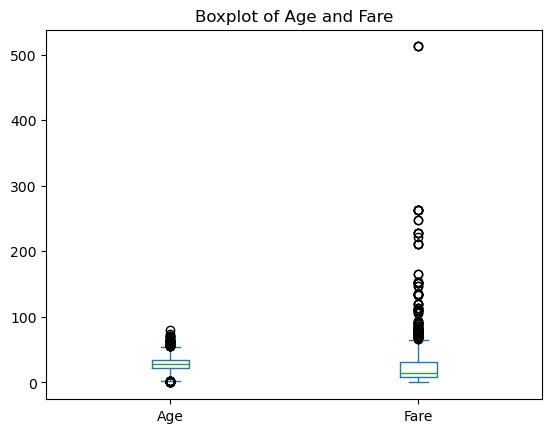

   Pclass  Sex       Age  SibSp  Parch      Fare  Embarked
0     1.0  1.0  0.271174  0.125    0.0  0.014151       1.0
1     0.0  0.0  0.472229  0.125    0.0  0.139136       0.0
2     1.0  0.0  0.321438  0.000    0.0  0.015469       1.0
3     0.0  0.0  0.434531  0.125    0.0  0.103644       1.0
4     1.0  1.0  0.434531  0.000    0.0  0.015713       1.0


In [40]:
# Boxplot to spot outliers
X[['Age', 'Fare']].plot(kind='box')
plt.title("Boxplot of Age and Fare")
plt.show()

# Min-Max normalization
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

print(X_scaled.head())

**(g)** Split the data into training and test sets and print the shapes of both.

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print(X_train.head())

Training set: (712, 7)
Test set: (179, 7)
     Pclass  Sex       Age  SibSp     Parch      Fare  Embarked
331     0.0  1.0  0.566474  0.000  0.000000  0.055628       1.0
733     0.5  1.0  0.283740  0.000  0.000000  0.025374       1.0
382     1.0  1.0  0.396833  0.000  0.000000  0.015469       1.0
704     1.0  1.0  0.321438  0.125  0.000000  0.015330       1.0
813     1.0  0.0  0.070118  0.500  0.333333  0.061045       1.0


# 2. Principal Component Analysis (PCA)
Write a Python program to apply PCA on the Iris dataset to reduce it from 4 features to 2.

**(a)** Standardize and plot a scatter plot before applying PCA.

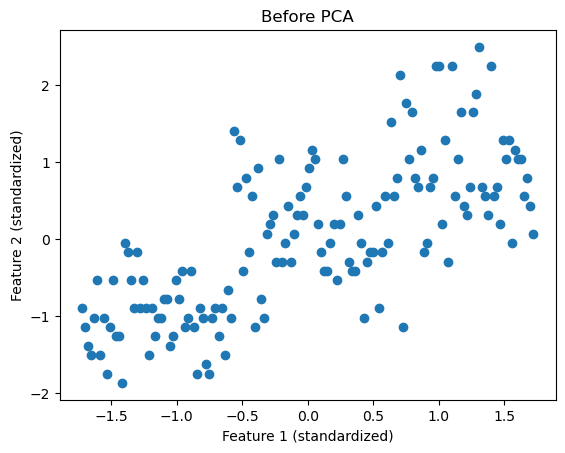

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv('iris.csv')
X = df.iloc[:, :4]      # 4 feature columns
y = df.iloc[:, -1]      # species column

X_std = StandardScaler().fit_transform(X)

# scatter plot of the first two standardized features
plt.scatter(X_std[:, 0], X_std[:, 1])
plt.xlabel("Feature 1 (standardized)")
plt.ylabel("Feature 2 (standardized)")
plt.title("Before PCA")
plt.show()

**(b)** Print the explained variance ratio of each principal component and the total variance retained.

In [43]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.70308855 0.22873259]
Total variance retained: 0.9318211437893086


**(c)** Print the first five rows of the reduced data.

In [44]:
reduced = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
print(reduced.head())

        PC1       PC2
0 -2.501021  0.451868
1 -2.279945 -0.696698
2 -2.559435 -0.383488
3 -2.476060 -0.636243
4 -2.579407  0.611050


**(d)** Plot the reduced data as a 2D scatter plot with a different colour for each species.

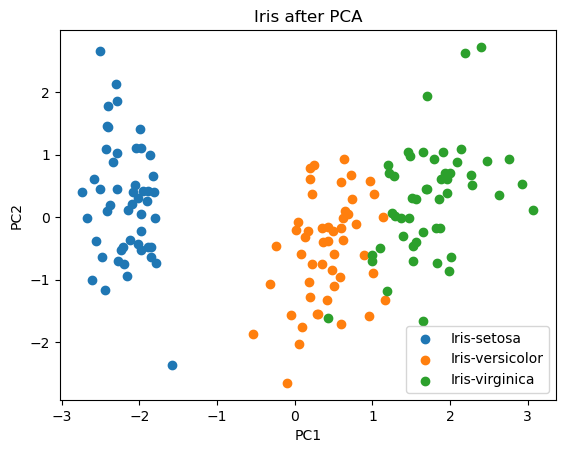

In [45]:
for species in y.unique():
    mask = (y == species)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=species)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Iris after PCA")
plt.legend()
plt.show()

# 3. Logistic Regression
Write a program to perform logistic regression on the Wine dataset (`wine.csv`).

In [46]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv('wine.csv')
X = df.iloc[:, 1:]      # features (every column after the first)
y = df.iloc[:, 0]       # target (wine class) is the FIRST column

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 1.0

Confusion Matrix:
 [[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]

Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        14
           3       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



# 4. Support Vector Machine (SVM)
Write a Python program to classify tumours as malignant or benign using SVM.

**Dataset:** Breast Cancer Wisconsin (`sklearn.datasets.load_breast_cancer`)

**(a)** Scale the features using `StandardScaler`.

In [47]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**(b)** Train two SVM models using linear and RBF kernels and print the accuracy of both.

In [48]:
linear_model = SVC(kernel='linear')
linear_model.fit(X_train, y_train)

rbf_model = SVC(kernel='rbf')
rbf_model.fit(X_train, y_train)

print("Linear kernel accuracy:", accuracy_score(y_test, linear_model.predict(X_test)))
print("RBF kernel accuracy:", accuracy_score(y_test, rbf_model.predict(X_test)))

Linear kernel accuracy: 0.956140350877193
RBF kernel accuracy: 0.9824561403508771


**(c)** Display the confusion matrix and print accuracy, precision, recall, F1-score.

In [49]:
y_pred = rbf_model.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))

Confusion Matrix:
 [[41  2]
 [ 0 71]]
Accuracy : 0.9824561403508771
Precision: 0.9726027397260274
Recall   : 1.0
F1-score : 0.9861111111111112


**(d)** Print the classification report.

In [50]:
print(classification_report(y_test, y_pred, target_names=data.target_names))

              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        43
      benign       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



# 5. K-Nearest Neighbours (KNN)
Write a Python program to implement KNN classification on the Iris dataset (`iris.csv`).

**(a)** Scale the features using `StandardScaler`.

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

df = pd.read_csv('iris.csv')
X = df.iloc[:, :4]
y = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**(b)** Classify the test set and print the correct and wrong predictions.

In [52]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

actual = list(y_test)
correct = 0
wrong = 0
for i in range(len(actual)):
    if actual[i] == y_pred[i]:
        correct += 1
        print("Correct: actual =", actual[i], "| predicted =", y_pred[i])
    else:
        wrong += 1
        print("WRONG  : actual =", actual[i], "| predicted =", y_pred[i])

print("\nTotal correct:", correct)
print("Total wrong:", wrong)

Correct: actual = Iris-versicolor | predicted = Iris-versicolor
Correct: actual = Iris-setosa | predicted = Iris-setosa
Correct: actual = Iris-virginica | predicted = Iris-virginica
Correct: actual = Iris-versicolor | predicted = Iris-versicolor
Correct: actual = Iris-versicolor | predicted = Iris-versicolor
Correct: actual = Iris-setosa | predicted = Iris-setosa
Correct: actual = Iris-versicolor | predicted = Iris-versicolor
Correct: actual = Iris-virginica | predicted = Iris-virginica
Correct: actual = Iris-versicolor | predicted = Iris-versicolor
Correct: actual = Iris-versicolor | predicted = Iris-versicolor
Correct: actual = Iris-virginica | predicted = Iris-virginica
Correct: actual = Iris-setosa | predicted = Iris-setosa
Correct: actual = Iris-setosa | predicted = Iris-setosa
Correct: actual = Iris-setosa | predicted = Iris-setosa
Correct: actual = Iris-setosa | predicted = Iris-setosa
Correct: actual = Iris-versicolor | predicted = Iris-versicolor
Correct: actual = Iris-virgini

**(c)** Vary k from 1 to 15, plot accuracy against k, and report the best value of k.

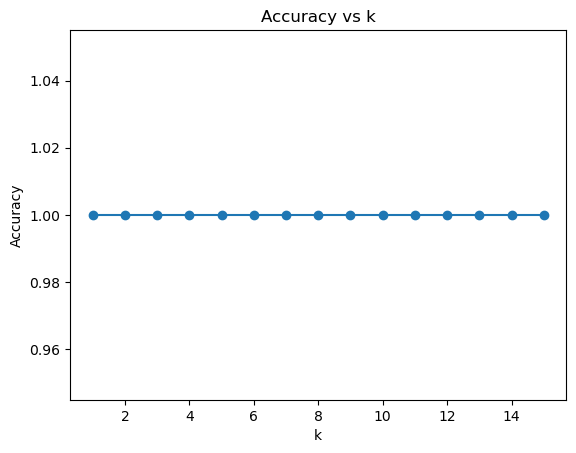

Best k: 1 with accuracy 1.0


In [53]:
k_values = range(1, 16)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    accuracies.append(accuracy_score(y_test, model.predict(X_test)))

plt.plot(k_values, accuracies, marker='o')
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Accuracy vs k")
plt.show()

best_k = k_values[accuracies.index(max(accuracies))]
print("Best k:", best_k, "with accuracy", max(accuracies))

# 6. Decision Tree
Write a classification program for implementing a decision tree using the playtennis dataset (`playtennis.csv`, 14 rows).

**(a)** Encode the categorical attributes and build the decision tree.

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

df = pd.read_csv('playtennis.csv')
print(df)

# one LabelEncoder per column (kept so we can reuse them later)
encoders = {}
for col in df.columns:
    encoders[col] = LabelEncoder()
    df[col] = encoders[col].fit_transform(df[col])

X = df.drop('Play Tennis', axis=1)
y = df['Play Tennis']

tree = DecisionTreeClassifier(criterion='entropy')
tree.fit(X, y)

     Outlook Temperature Humidity    Wind Play Tennis
0      Sunny         Hot     High    Weak          No
1      Sunny         Hot     High  Strong          No
2   Overcast         Hot     High    Weak         Yes
3       Rain        Mild     High    Weak         Yes
4       Rain        Cool   Normal    Weak         Yes
5       Rain        Cool   Normal  Strong          No
6   Overcast        Cool   Normal  Strong         Yes
7      Sunny        Mild     High    Weak          No
8      Sunny        Cool   Normal    Weak         Yes
9       Rain        Mild   Normal    Weak         Yes
10     Sunny        Mild   Normal  Strong         Yes
11  Overcast        Mild     High  Strong         Yes
12  Overcast         Hot   Normal    Weak         Yes
13      Rain        Mild     High  Strong          No


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sa

**(b)** Print the tree in text form using `export_text` and display it graphically using `plot_tree`.

|--- Outlook <= 0.50
|   |--- class: 1
|--- Outlook >  0.50
|   |--- Humidity <= 0.50
|   |   |--- Outlook <= 1.50
|   |   |   |--- Wind <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Wind >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Outlook >  1.50
|   |   |   |--- class: 0
|   |--- Humidity >  0.50
|   |   |--- Wind <= 0.50
|   |   |   |--- Temperature <= 1.00
|   |   |   |   |--- class: 0
|   |   |   |--- Temperature >  1.00
|   |   |   |   |--- class: 1
|   |   |--- Wind >  0.50
|   |   |   |--- class: 1



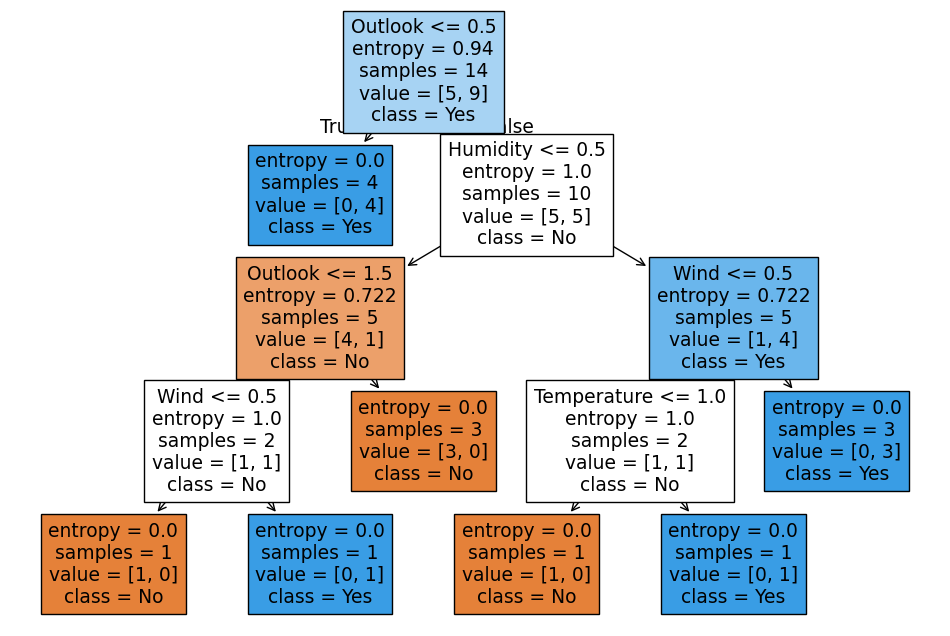

In [55]:
print(export_text(tree, feature_names=list(X.columns)))

plt.figure(figsize=(12, 8))
plot_tree(tree, feature_names=X.columns, class_names=encoders['Play Tennis'].classes_, filled=True)
plt.show()

**(c)** Print the accuracy of the tree on the training data.

In [56]:
print("Training accuracy:", tree.score(X, y))

Training accuracy: 1.0


**(d)** Classify the new sample: Outlook = Sunny, Temperature = Cool, Humidity = High, Wind = Strong.

In [57]:
new_sample = {'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'High', 'Wind': 'Strong'}

# encode the sample with the same encoders used for training
encoded = [encoders[col].transform([val])[0] for col, val in new_sample.items()]
sample_df = pd.DataFrame([encoded], columns=X.columns)

pred = tree.predict(sample_df)
print("Prediction:", encoders['Play Tennis'].inverse_transform(pred)[0])

Prediction: No


# 7. K-Means Clustering
Write a Python program to implement K-Means clustering using the Mall Customers dataset (`mall_customers.csv`).

**(a)** Use the Elbow method (k = 1 to 10) to find the optimal number of clusters and plot the elbow curve.

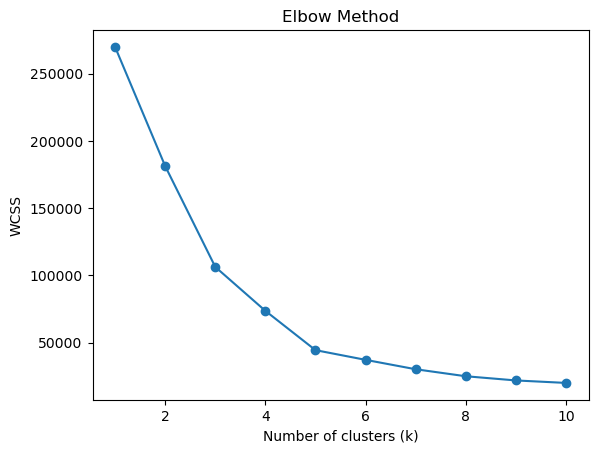

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.read_csv('mall_customers.csv')

# Annual Income and Spending Score columns
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

**(b)** Apply K-Means with the optimal k and plot the clusters with their centroids marked.

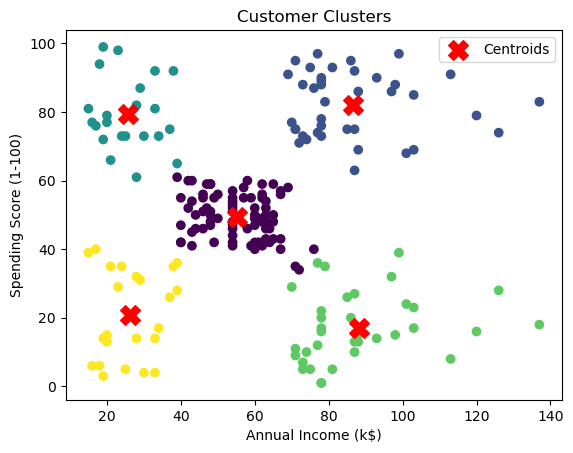

In [59]:
optimal_k = 5   # the elbow in the curve above appears at k = 5

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c='red', marker='X', s=200, label='Centroids')
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Clusters")
plt.legend()
plt.show()

# 8. Artificial Neural Network (ANN)
Write a Python program to build a multilayer perceptron using `MLPClassifier` to predict diabetes.

**Dataset:** `diabetes.csv` (Pima Indians Diabetes, 768 rows)

**(a)** Scale the features using `StandardScaler`.

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

df = pd.read_csv('diabetes.csv')
X = df.iloc[:, :-1]     # feature columns
y = df.iloc[:, -1]      # last column = diabetes outcome (0/1)

# turn any text columns (e.g. gender) into 0/1 columns so the network can use them
X = pd.get_dummies(X, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**(b)** Build the network with two hidden layers (16 and 8 neurons) using ReLU activation and train for up to 500 iterations.

In [61]:
mlp = MLPClassifier(hidden_layer_sizes=(16, 8), activation='relu', max_iter=500, random_state=42)
mlp.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(16, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


**(c)** Plot the training loss curve using `loss_curve_`.

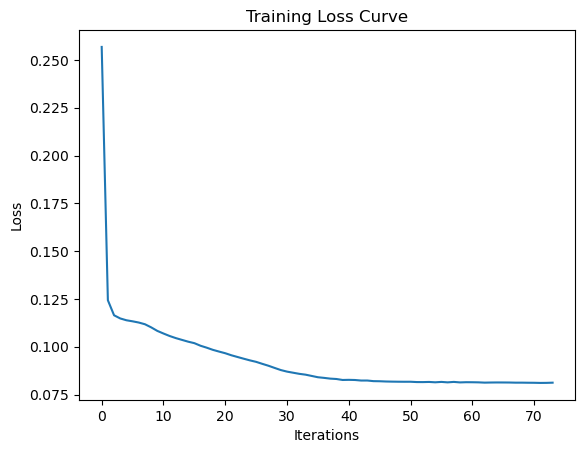

In [62]:
plt.plot(mlp.loss_curve_)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.show()

**(d)** Print the test accuracy and confusion matrix.

In [63]:
y_pred = mlp.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Test accuracy: 0.9719
Confusion Matrix:
 [[18277    15]
 [  547  1161]]


# 9. Convolutional Neural Network (CNN)
Write a Python program to build a CNN using Keras to classify handwritten digits.

**Dataset:** Digits (`sklearn.datasets.load_digits`, 1,797 images of 8×8 pixels)

**(a)** Reshape the images to 8×8×1 and normalize the pixel values.

In [64]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

digits = load_digits()
X = digits.images.reshape(-1, 8, 8, 1)   # 8x8x1
X = X / 16.0                             # pixel values are 0-16, so scale to 0-1
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

ModuleNotFoundError: No module named 'tensorflow'

**(b)** Build the model with one Conv2D layer (16 filters, 3×3), one MaxPooling layer, a Flatten layer, a Dense hidden layer and a softmax output layer.

In [ ]:
model = Sequential([
    Conv2D(16, (3, 3), activation='relu', input_shape=(8, 8, 1)),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

**(c)** Train for 20 epochs and plot the accuracy curve.

In [ ]:
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_test, y_test))

plt.plot(history.history['accuracy'], label='Train accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve")
plt.legend()
plt.show()

**(d)** Print the test accuracy and the predicted versus actual labels for five test images.

In [ ]:
loss, acc = model.evaluate(X_test, y_test)
print("Test accuracy:", acc)

pred = np.argmax(model.predict(X_test[:5]), axis=1)
print("Predicted:", pred)
print("Actual   :", y_test[:5])